In [2]:
import torch, torch.nn as nn
import math, copy
print(torch.__version__)

2.11.0+cpu


In [19]:
import copy, os
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

**RULES**

- R1. Three-way split: test = 20% of all rows (random_state=42, stratify), then validation = 25% of the remaining rows (random_state=42, stratify). So about 60/20/20.

- R2. Pixels are divided by 16.0 (their fixed maximum). No statistics are taken from any split.

- R3. The model returns raw logits (no Softmax inside). Loss = nn.CrossEntropyLoss(). Optimizer = Adam,
lr = 0.01. Mini-batches of 64, 30 epochs, for every model.

- R4. Candidates: A (one Linear layer), B (one hidden layer), C (two hidden layers). For each model, take its BEST epoch (lowest validation loss) and compare validation ACCURACY at that epoch. A bigger model is
chosen only if it beats the simpler one by MORE than 0.01 accuracy; otherwise choose the simpler.

- R5. The test set is opened ONCE, for the chosen model only, after saving and re-loading it.


In [20]:
#PART 1. DATA
d = load_digits()
X, y = d.data, d.target
print(X.shape, X.min(), X.max())
print(np.bincount(y))

(1797, 64) 0.0 16.0
[178 182 177 183 181 182 181 179 174 180]


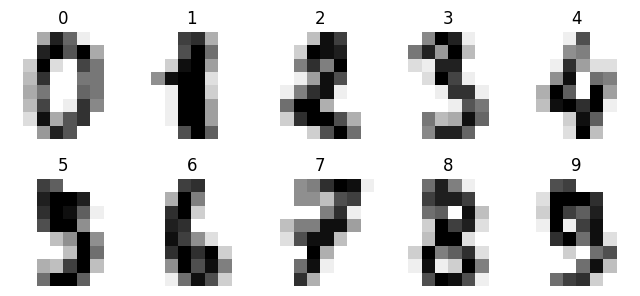

In [21]:
fig, axes = plt.subplots(2, 5, figsize=(8, 3.5))
for ax, img, lab in zip(axes.ravel(), d.images[:10], d.target[:10]):
  ax.imshow(img, cmap="gray_r")
  ax.set_title(lab)
  ax.axis("off")
plt.show()

In [22]:
X_tv, X_te, y_tv, y_te = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
Xtr, Xval, ytr, yval = train_test_split(X_tv, y_tv, test_size=0.25, random_state=42, stratify=y_tv)

Xtr, Xval, X_te = Xtr / 16.0, Xval / 16.0, X_te / 16.0
print(Xtr.shape, Xval.shape, X_te.shape)
print(Xtr.max(), round(Xtr.mean(), 4))
print("majority baseline (val):", round(np.bincount(yval).max() / len(yval), 4))


(1077, 64) (360, 64) (360, 64)
1.0 0.3065
majority baseline (val): 0.1028


- Day 14 fitted the scaler on the TRAIN rows only. Why is dividing by 16.0 for all three sets still
leak-free? (Think: where does the number 16 come from?)
  * The 16 is not calculated from any rows. It is the fixed maximum of the pixel scale (every pixel is 0 to 16), so train, validation and test are all divided by the same constant and no information from validation or test flows into training.

- Why is 0.1028 the floor that any model must beat?
  * Because it is the accuracy of a model that has learnt nothing: always guessing the most common digit in validation gets 37 of 360 right = 0.1028. Any real model has to beat this.

In [23]:
class DigitsDataset(Dataset):
  def __init__(self, X, y):
    self.X = torch.tensor(X, dtype=torch.float32)
    self.y = torch.tensor(y, dtype=torch.long)

  def __len__(self):
    return len(self.y)

  def __getitem__(self, idx):
    return self.X[idx], self.y[idx]

In [24]:
train_ds, val_ds, test_ds = DigitsDataset(Xtr, ytr), DigitsDataset(Xval, yval), DigitsDataset(X_te, y_te)
print(len(train_ds), len(val_ds), len(test_ds))
print(train_ds[0][0].shape, train_ds[0][0].dtype, train_ds[0][1], train_ds[0][1].dtype)

1077 360 360
torch.Size([64]) torch.float32 tensor(3) torch.int64


In [26]:
#PART 2. DATASET AND DATALOADER
def new_train_loader():
  return DataLoader(train_ds, batch_size=64, shuffle=True, generator=torch.Generator().manual_seed(42))

val_loader = DataLoader(val_ds, batch_size=256)
test_loader = DataLoader(test_ds, batch_size=256)

xb, yb = next(iter(new_train_loader()))
print(xb.shape, yb.shape, xb.dtype, yb.dtype)
print(len(new_train_loader()), len(val_loader))
print("rows in the last train batch:", len(train_ds) - (len(new_train_loader()) - 1) * 64)

torch.Size([64, 64]) torch.Size([64]) torch.float32 torch.int64
17 2
rows in the last train batch: 53


- Why are the labels dtype long with shape (N,), unlike the (N, 1) float labels you used for churn?
  * CrossEntropyLoss picks the logit of the correct class by its index, so each row needs one class number (0 to 9) as an integer (long), shape (N,). In churn there was one yes/no probability per row, so the labels were float 0/1 in shape (N, 1) for BCE.

- 1077 rows with batch size 64 gives 17 batches. Show the arithmetic and say why the last one has 53.
  * 1077 / 64 = 16.8, so 16 full batches use 16 x 64 = 1024 rows. The remaining 1077 - 1024 = 53 rows form the 17th batch, so the last one has 53 (drop_last is False, so nothing is thrown away).

In [27]:
#PART 3. TWO BASELINES BEFORE ANY NEURAL NETWORK\
lr = LogisticRegression(max_iter=1000)
lr.fit(Xtr, ytr)
print("sk learn logistic regression val accuracy:", round(lr.score(Xval, yval), 4))

sk learn logistic regression val accuracy: 0.9722


- if your PyTorch network scored 0.95 here, what would that tell you?
  * It would tell me my network is worse than a simple logistic regression (0.9722) on the same split, so something is wrong or unfinished (pipeline bug, learning rate, too few epochs). A neural network is not automatically better, so the baseline is the bar it has to clear.

In [ ]:
#PART 4. HELPERS
loss_fn = nn.CrossEntropyLoss()

def run_epoch(model, loader, opt=None):
  train = opt is not None
  model.train() if train else model.eval()
  tot, correct, n = 0.0, 0, 0
  with torch.set_grad_enabled(train):
    for xb, yb in loader:
      logits = model(xb)
      loss = loss_fn(logits, yb)
      if train:
        loss.backward()
        opt.step()
        opt.zero_grad()
      tot += loss.item() * len(yb)
      correct += (logits.argmax(dim=1) == yb).sum().item()
      n += len(yb)
  return tot / n, correct / n

def train_model(model, opt, epochs):
  loader = new_train_loader()
  h = {"tl": [], "ta": [], "vl": [], "va": []}
  best = {"vl": float("inf")}
  for e in range(1, epochs + 1):
    tl_, ta = run_epoch(model, loader, opt)
    vl_, va = run_epoch(model, val_loader)
    h["tl"].append(tl_)
    h["ta"].append(ta)
    h["vl"].append(vl_)
    h["va"].append(va)

    if vl_ < best["vl"]:
      best = {"vl": vl_, "va": va, "epoch": e, "state": copy.deepcopy(model.state_dict())}
  return h, best

def mk(kind):
  torch.manual_seed(42)
  if kind == "A": return nn.Linear(64, 10)
  if kind == "B": return nn.Sequential(nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 10))
  return nn.Sequential(nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 10))

In [31]:
for k in "ABC":
  print(k, sum(p.numel() for p in mk(k).parameters()), "parameters")
print("untrained C:", [round(v, 4) for v in run_epoch(mk("C"), val_loader)])

A 650 parameters
B 4810 parameters
C 17226 parameters
untrained C: [2.3032, 0.1222]


Count the parameters by hand, in the notebook:
A = 64 x 10 + 10 = 650

B = (64 x 64 + 64) + (64 x 10 + 10) = 4810

C = (64 x 128 + 128) + (128 x 64 + 64) + (64 x 10 + 10) = 17226

- The untrained model has validation loss 2.3032 and accuracy 0.1222. Which two numbers from this guide do those match, and what does that tell you about your pipeline?
  * 0.1222 is about 0.10 (1 in 10) and 2.3032 is about ln(10) = 2.3026. An untrained model guesses all 10 digits about equally, so accuracy should be near 1/10 and loss near ln(10). It matches, so my pipeline (raw logits, CrossEntropyLoss, long labels, loaders) is wired correctly.

- In train_model, why is the best state saved with a deepcopy and with VALIDATION loss, not train loss?
  * state_dict() returns references to the live weights, which keep changing every epoch, so only a deepcopy freezes the best epoch. I use validation loss because train loss keeps falling even when the model just memorises (C: train loss 0.0006); only validation shows how the model does on rows it has not trained on.

In [35]:
#PART 5. TRAIN THE THREE MODELS AND CHOOSE (rule R4)
R = {}
for k in "ABC":
  m = mk(k)
  h, best = train_model(m, torch.optim.Adam(m.parameters(), lr=0.01), 30)
  R[k] = (m, h, best)
  print(k, "best epoch", best["epoch"], "val loss", round(best["vl"], 4), "val acc", round(best["va"], 4))
  print("   epoch 1: train loss", round(h["tl"][0], 4), "train acc", round(h["ta"][0], 4),
              "| val loss", round(h["vl"][0], 4), "val acc", round(h["va"][0], 4))
  print("   epoch 5: train loss", round(h["tl"][4], 4), "train acc", round(h["ta"][4], 4),
              "| val loss", round(h["vl"][4], 4), "val acc", round(h["va"][4], 4))
  print("   epoch 10: train loss", round(h["tl"][9], 4), "train acc", round(h["ta"][9], 4),
              "| val loss", round(h["vl"][9], 4), "val acc", round(h["va"][9], 4))
  print("   epoch 20: train loss", round(h["tl"][19], 4), "train acc", round(h["ta"][19], 4),
              "| val loss", round(h["vl"][19], 4), "val acc", round(h["va"][19], 4))
  print("   epoch 30: train loss", round(h["tl"][-1], 4), "train acc", round(h["ta"][-1], 4),
              "| val loss", round(h["vl"][-1], 4), "val acc", round(h["va"][-1], 4))

A best epoch 30 val loss 0.1853 val acc 0.9556
   epoch 1: train loss 2.0242 train acc 0.4615 | val loss 1.6025 val acc 0.8139
   epoch 5: train loss 0.5705 train acc 0.9248 | val loss 0.5584 val acc 0.9194
   epoch 10: train loss 0.3179 train acc 0.9434 | val loss 0.3471 val acc 0.9472
   epoch 20: train loss 0.188 train acc 0.9656 | val loss 0.2301 val acc 0.9528
   epoch 30: train loss 0.1372 train acc 0.9796 | val loss 0.1853 val acc 0.9556
B best epoch 29 val loss 0.0873 val acc 0.975
   epoch 1: train loss 1.7433 train acc 0.5942 | val loss 0.9949 val acc 0.8528
   epoch 5: train loss 0.1628 train acc 0.9517 | val loss 0.1985 val acc 0.9389
   epoch 10: train loss 0.0805 train acc 0.9796 | val loss 0.141 val acc 0.9667
   epoch 20: train loss 0.0276 train acc 0.9963 | val loss 0.1001 val acc 0.9667
   epoch 30: train loss 0.0187 train acc 0.9963 | val loss 0.1061 val acc 0.9667
C best epoch 19 val loss 0.0731 val acc 0.9778
   epoch 1: train loss 1.5304 train acc 0.5311 | val los

- Does B beat A by more than 0.01 validation accuracy at their best epochs?
  * Yes. B at its best epoch has val accuracy 0.975 and A has 0.9556, so B - A = 0.0194, which is more than 0.01 (about 7 images). B earns its extra size.

- Does C beat B by more than 0.01?
  * No. C has 0.9778 and B has 0.975, so C - B = 0.0028, less than 0.01.

- Which model do you choose? (Notice: 1 validation image = 1/360 = 0.0028 accuracy. How many images is the C-over-B gap?)
  * I choose B. The C-over-B gap is 0.0028 x 360 = 1 validation image, which is noise, while C has 17226 parameters against B's 4810 and memorises the training rows. By rule R4 a tie goes to the simpler model.

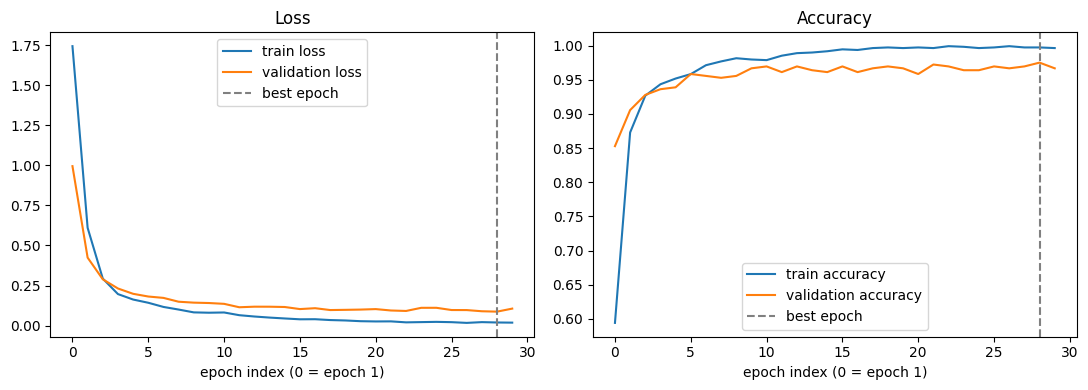

In [52]:
ch = "B"                        # your choice from rule R4: "A", "B" or "C"
m, h, best = R[ch]                 # R[k] = (model, history, best), as you stored it in Part 5

fig, ax = plt.subplots(1, 2, figsize=(11, 4))        # subplots: 1 row, 2 panels side by side

# left panel: loss
ax[0].plot(h["tl"], label="train loss")
ax[0].plot(h["vl"], label="validation loss")     # the history key for validation loss
ax[0].axvline(best["epoch"] - 1, color="gray", linestyle="--", label="best epoch")
ax[0].set_title("Loss")
ax[0].set_xlabel("epoch index (0 = epoch 1)")
ax[0].legend()

# right panel: accuracy
ax[1].plot(h["ta"], label="train accuracy")      # the history key for train accuracy
ax[1].plot(h["va"], label="validation accuracy") # the history key for validation accuracy
ax[1].axvline(best["epoch"] - 1, color="gray", linestyle="--", label="best epoch")
ax[1].set_title("Accuracy")
ax[1].set_xlabel("epoch index (0 = epoch 1)")
ax[1].legend()

fig.tight_layout()
plt.show()                                       # show

- A: its train loss is still 0.1372 at epoch 30 and falling. What does that say about a single Linear layer for this problem (underfitting? not converged? both)?
  * A is not converged: the train loss is still falling at epoch 30 (0.1372), so it needs more epochs. It is also limited as a model, because one Linear layer cannot reach B's train loss (0.0187), so it is both, though A is already decent at 0.9556 val accuracy.

- C: train accuracy is 1.0 and train loss is 0.0006, but the validation loss is 0.0834. What is C doing
to the training rows, and how much validation accuracy did it buy over B?
  * C is memorising the training rows: train accuracy 1.0 and train loss 0.0006, while the validation loss stays at 0.0834. At its best epoch it bought only +0.0028 validation accuracy over B (0.9778 against 0.975, one image), which is not worth 17226 parameters.

- Look at B's validation loss over epochs 25 to 30: 0.1112, 0.0973, 0.0970, 0.0897, 0.0873, 0.1061. Is "best epoch 29" a sharp optimum, or one lucky point on a jagged plateau? What does this suggest about stopping rules on Day 17?
  * It is one lucky point on a jagged plateau, not a sharp optimum: epochs 25 to 30 bounce between 0.0873 and 0.1112 and go back up to 0.1061 at epoch 30. So on Day 17 early stopping needs a patience of several epochs (a short patience would stop on a random bump) and should restore the best weights.

- The plot of B: where does the validation loss stop improving noticeably?
  * Around epoch 20: the loss falls fast at first (0.9949 at epoch 1, 0.1985 at epoch 5, 0.141 at epoch 10, 0.1001 at epoch 20), and after that it just wobbles between about 0.087 and 0.11 without a clear trend.


In [49]:
#PART 6. SAVE AND LOAD THE CHOSEN MODEL
mp = mk("B")
op = torch.optim.Adam(mp.parameters(), lr=0.01)
lp = new_train_loader()

for e in range(10):
  run_epoch(mp, lp, op)
ref = mp.state_dict()
cp = copy.deepcopy(mp.state_dict())

for e in range(5):
  run_epoch(mp, lp, op)
for name, sd in (("reference", ref), ("deepcopy", cp)):
  t = mk("B")
  t.load_state_dict(sd)
  print(name, [round(v, 4) for v in run_epoch(t, val_loader)])

reference [0.1162, 0.9611]
deepcopy [0.141, 0.9667]


- what did the "reference" snapshot actually contain, and why would saving it have been a silent bug?
  * state_dict() does not copy; the reference points at the same live weight tensors, so after 5 more epochs it contained the epoch-15 weights (val loss 0.1162, acc 0.9611), not the epoch-10 weights I meant to save (the deepcopy gave 0.141, 0.9667). It would be a silent bug because there is no error: the code runs and saves a file, but it is the wrong (later) weights.


In [50]:
best = R["B"][2]
torch.save({"state_dict": best["state"], "epoch": best["epoch"], "val_acc": best["va"]}, "digit_mlp.pt")
print(os.path.getsize("digit_mlp.pt"), "bytes")
ck = torch.load("digit_mlp.pt")
print(list(ck.keys()), ck["epoch"], round(ck["val_acc"], 4))
print(list(ck["state_dict"].keys()))

21745 bytes
['state_dict', 'epoch', 'val_acc'] 29 0.975
['0.weight', '0.bias', '2.weight', '2.bias']


In [51]:
torch.manual_seed(7)
new = nn.Sequential(nn.Linear(64,64), nn.ReLU(), nn.Linear(64,10))
print("fresh:", [round(v, 4) for v in run_epoch(new, val_loader)])
new.load_state_dict(ck["state_dict"])
print("loaded:", [round(v, 4) for v in run_epoch(new, val_loader)])

ref_m = mk("B")
ref_m.eval()
new.eval()
with torch.no_grad():
  print("same logits:", torch.equal(ref_m(val_ds.X), new(val_ds.X)))

fresh: [2.3306, 0.0944]
loaded: [0.0873, 0.975]
same logits: False


- Name the three things that must match for load_state_dict to work (hint: architecture shapes, key names, and one more thing: what file are you loading?).
  * (1) The architecture must have the same layer shapes (64-64-10 for B), (2) the key names must match (0.weight, 0.bias, 2.weight, 2.bias, so the same Sequential layout), and (3) I must load the right thing from the file: the weights dictionary ck["state_dict"], not the whole checkpoint dict, which also holds epoch and val_acc.

- Why does "loaded" equal B's best-epoch numbers from Part 5 exactly, not B's epoch-30 numbers?
  * Because I saved best["state"], the deepcopy taken at B's best epoch 29 (lowest validation loss, 0.0873, accuracy 0.975), not the final epoch-30 weights (0.1061, 0.9667). Loading restores exactly those weights, so the numbers are identical.


In [54]:
#PART 7. OPEN THE TEST SET ONCE, THEN READ THE ERRORS
tloss, tacc = run_epoch(new, test_loader)
print("Test Loss", round(tloss, 4), "accuracy", round(tacc, 4))
with torch.no_grad():
  pred = new(test_ds.X).argmax(dim=1).numpy()
cm = confusion_matrix(y_te, pred)
print(cm)
print("wrong:", int((pred != y_te).sum()))
recall = cm.diagonal() / cm.sum(axis=1)
print([round(float(r), 3) for r in recall])

Test Loss 0.1079 accuracy 0.9639
[[34  0  1  0  1  0  0  0  0  0]
 [ 0 32  0  0  0  0  0  0  3  1]
 [ 0  0 35  0  0  0  0  0  0  0]
 [ 0  0  0 37  0  0  0  0  0  0]
 [ 0  0  0  0 36  0  0  0  0  0]
 [ 0  0  0  0  0 37  0  0  0  0]
 [ 0  0  0  0  0  0 35  0  1  0]
 [ 0  0  0  0  0  0  0 36  0  0]
 [ 0  4  0  0  0  0  0  0 31  0]
 [ 0  0  0  0  1  0  0  0  1 34]]
wrong: 13
[0.944, 0.889, 1.0, 1.0, 1.0, 1.0, 0.972, 1.0, 0.886, 0.944]


In [55]:
pairs = []
for i in range(10):
  for j in range(10):
    if i == j:
      continue
    if cm[i, j] > 0:
      pairs.append((int(cm[i, j]), i, j))
pairs.sort(reverse=True)
print(pairs[:3])

[(4, 8, 1), (3, 1, 8), (1, 9, 8)]


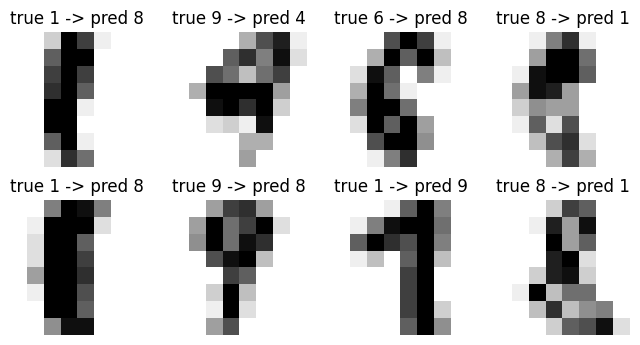

In [56]:
wrong_idx = np.where(pred != y_te)[0][:8]
fig, axes = plt.subplots(2, 4, figsize=(8, 4))
for ax, i in zip(axes.ravel(), wrong_idx):
    ax.imshow(X_te[i].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"true {y_te[i]} -> pred {pred[i]}"); ax.axis("off")
plt.show()


- Validation accuracy of the chosen model was 0.975 and test accuracy is 0.9639. Why is the test number
expected to be a little LOWER than the best-epoch validation number? (Think: what was chosen on the
validation set, and which two choices did it influence?)
  * The validation set was used to pick the best epoch (29) and to pick the model (B by rule R4), so the validation number is the best of many tries and a bit optimistic. The test rows influenced neither choice, so the test result is an honest estimate and expected to be a little lower (0.9639 against 0.975).

- Which two digits does the network confuse most, and look at your 8 images: would a person hesitate on
any of them?
  * 8 and 1: the network predicted 1 for a true 8 four times and 8 for a true 1 three times (recall 0.886 for 8 and 0.889 for 1). On an 8x8 image the strokes are only a few pixels, so I think a person would hesitate on a few of the blurry ones.

- Your network scores 0.9639 and sklearn's logistic regression 0.9556. That is 3 test images out of 360.
Is that a real improvement? One sentence.
  * No. 0.0083 is 3 images out of 360, which is within the noise of one split; I would need other seeds or more test data to claim it is better.

- Why is a flat 64-number input a limit for images, and what would a convolution (Day 18) add?
  * A flat vector of 64 numbers throws away where pixels sit: the network does not know that two pixels are neighbours, so the same digit shifted by one pixel looks like a completely different input. A convolution slides small filters over neighbourhoods to find local shapes such as strokes and curves, with shared weights, so it uses the 2D layout and copes better with position.

- Would you ship this model for real handwriting from a phone camera? Name one reason it would break.
  * No. These images are clean 8x8 scans that were centred and scaled; a phone photo has a different resolution, lighting, background, pen thickness and position, so the inputs look different from the training data and the accuracy would drop.

**Conclusion**

- **The pipeline, step by step.** Load the 8x8 digits, split 60/20/20 (stratified), divide pixels by 16, wrap them in a Dataset and DataLoader (batch 64, 17 batches, the last one 53 rows), build a model that returns raw logits, train with CrossEntropyLoss and Adam (lr 0.01) for 30 epochs, check validation every epoch, save the best state, load it back, and open the test set once.

- **Multiclass is not binary.** The model has 10 logits, CrossEntropyLoss applies the softmax inside, and labels are long integers of shape (N,); BCE is for one yes/no output. An untrained model gave loss 2.3032 (ln 10 = 2.3026) and accuracy 0.1222, and the majority baseline is 0.1028, so I knew the pipeline was right before training. The sklearn logistic regression (0.9722 val) was the bar to clear.

- **train, eval and no_grad.** model.train() is for the update loop, model.eval() for validation and test (it matters once Dropout is in the model), and torch.no_grad() (or set_grad_enabled(False)) switches off gradient tracking when I only predict.

- **Saving.** state_dict() returns references, so the "reference" snapshot silently held the later weights (0.1162, 0.9611) while the deepcopy kept the right ones (0.141, 0.9667). I saved a checkpoint dict (state_dict, epoch, val_acc); the loaded model reproduced the best epoch exactly (0.0873, 0.975).

- **Choosing the model with R4.** Best-epoch validation accuracy: A 0.9556, B 0.975, C 0.9778. B beats A by 0.0194 (more than 0.01) but C beats B by only 0.0028 (one image), so I chose B (4810 parameters). C memorised the training set (train accuracy 1.0, train loss 0.0006). B's validation curve is jagged, so its best epoch (29) is one lucky point on a plateau.

- **Test result.** Test loss 0.1079 and accuracy 0.9639 (13 wrong out of 360), a bit below the 0.975 validation number because the epoch and the model were chosen on validation. It is 3 images better than sklearn (0.9556), which is not a real difference.

- **Errors.** The confusion matrix shows 8 to 1 (4 times) and 1 to 8 (3 times) as the most confused pair; recall is lowest for 8 (0.886) and 1 (0.889). Such errors are plausible on 8x8 images.

- **Next steps.** Day 17 (dropout, weight decay, early stopping, learning-rate scheduling, augmentation) to control the overfitting seen in C and the jagged curve of B, and Day 18 (CNN) to use the 2D structure of images instead of a flat vector.

*README note:* Day 16 mini project, Digit Classifier: a PyTorch MLP (64-64-10) reaches test accuracy 0.9639 (validation 0.975), chosen by rule R4 over a linear model and a larger model.
